## Goal of the ML section
### Building a model that can flag high-risk appointments in advnce and understand which features drive the predictions.

In [1]:
# Importing required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

# Load cleaned data
df = pd.read_csv('C:\\Users\\afola\\Desktop\\SUNDAY\\Python_Projects\\python_tutorial_2\\GET_Analysis (2)\\GET_Analysis\\my_project\\data\\appointments_cleansed.csv')

#creating target
df['No_Show_Binary'] = df['No_Show'].map({'No':0, 'Yes':1})

df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_received,No_Show,Waiting_Days,Appointment_Weekday,Scheduled_Weekday,Timing,Age_Group,No_Show_Binary
0,29872499824296,5642903,F,2016-04-29 00:00:00+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,0,Friday,Friday,Same Day,Elderly,0
1,558997776694438,5642503,M,2016-04-29 00:00:00+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,0,Friday,Friday,Same Day,Adult,0
2,4262962299951,5642549,F,2016-04-29 00:00:00+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,0,Friday,Friday,Same Day,Elderly,0
3,867951213174,5642828,F,2016-04-29 00:00:00+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,0,Friday,Friday,Same Day,Child,0
4,8841186448183,5642494,F,2016-04-29 00:00:00+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,0,Friday,Friday,Same Day,Adult,0


In [ ]:
os.makedirs('visuals', exist_ok=True)
sns.set_theme(style= "whitegrid", palette="pastel")

def save(name):
    plt.tight_layout()
    plt.savefig(f'visuals/{name}.png', dpi=150)
    plt.show()

: 

In [ ]:
print(df.shape)
print(df.info())
print(df.columns)


(110521, 20)
<class 'pandas.DataFrame'>
RangeIndex: 110521 entries, 0 to 110520
Data columns (total 20 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   PatientId            110521 non-null  int64
 1   AppointmentID        110521 non-null  int64
 2   Gender               110521 non-null  str  
 3   ScheduledDay         110521 non-null  str  
 4   AppointmentDay       110521 non-null  str  
 5   Age                  110521 non-null  int64
 6   Neighbourhood        110521 non-null  str  
 7   Scholarship          110521 non-null  int64
 8   Hypertension         110521 non-null  int64
 9   Diabetes             110521 non-null  int64
 10  Alcoholism           110521 non-null  int64
 11  Handicap             110521 non-null  int64
 12  SMS_received         110521 non-null  int64
 13  No_Show              110521 non-null  str  
 14  Waiting_Days         110521 non-null  int64
 15  Appointment_Weekday  110521 non-null  str  
 16  

: 

In [ ]:
df['No_Show_Binary'].value_counts(normalize= True)

No_Show_Binary
0    0.798102
1    0.201898
Name: proportion, dtype: float64

: 

In [ ]:
# Selecting Necessary Features and the target
Features= ['Gender', 
           "Age", 
           'Scholarship', 
           'Hypertension', 
           'Diabetes', 
           'Alcoholism', 
           'Handicap', 
           'SMS_received',
           'Waiting_Days',
           'Timing', 
           'Age_Group', 
           'Appointment_Weekday']
Target = 'No_Show_Binary'

X = df[Features].copy()
y = df[Target].copy()

print("Selected FEatures:")
print(X.columns.tolist())
print('\nTarget distribution:')
print (y.value_counts(normalize = True))

Selected FEatures:
['Gender', 'Age', 'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMS_received', 'Waiting_Days', 'Timing', 'Age_Group', 'Appointment_Weekday']

Target distribution:
No_Show_Binary
0    0.798102
1    0.201898
Name: proportion, dtype: float64


: 

In [ ]:
# Encoding the categorical columns
categorical_cols = ['Gender', "Timing", "Age_Group", "Appointment_Weekday"]

X_encoded =  X.copy()

# Label encoding for tree-based models (Random Forest later)
le_dict ={}
for col  in categorical_cols:
    le = LabelEncoder()
    X_encoded[col] =le.fit_transform(X_encoded[col])
    le_dict[col] = le

print(X_encoded.head())
print("\nData typees after encoding:")
print(X_encoded.dtypes)


   Gender  Age  Scholarship  Hypertension  Diabetes  Alcoholism  Handicap  \
0       0   62            0             1         0           0         0   
1       1   56            0             0         0           0         0   
2       0   62            0             0         0           0         0   
3       0    8            0             0         0           0         0   
4       0   56            0             1         1           0         0   

   SMS_received  Waiting_Days  Timing  Age_Group  Appointment_Weekday  
0             0             0       2          2                    0  
1             0             0       2          0                    0  
2             0             0       2          2                    0  
3             0             0       2          1                    0  
4             0             0       2          0                    0  

Data typees after encoding:
Gender                 int64
Age                    int64
Scholarship       

: 

In [ ]:
# Spliting into Train and Test
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, 
    test_size=0.20,
    random_state =42,
    stratify=y)

print('Training set:', X_train.shape)
print('Testing set:', X_test.shape)
print("\nTRain target distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (88416, 12)
Testing set: (22105, 12)

TRain target distribution:
No_Show_Binary
0    0.798
1    0.202
Name: proportion, dtype: float64

Test target distribution:
No_Show_Binary
0    0.798
1    0.202
Name: proportion, dtype: float64


: 

In [ ]:
#Using the Logistic Regression model
log_reg = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
log_reg.fit(X_train, y_train)

#Predictions from the model
y_pred_lr = log_reg.predict(X_test)
y_prob_lr = log_reg.predict_proba(X_test)[:, 1]

#Evaluation
print("=== Logistic Regression Results====")
print(confusion_matrix(y_test, y_pred_lr))

print('Confusion Matrix:')
print(confusion_matrix(y_test,y_pred_lr))

print("\nROC_AUC Score", round(roc_auc_score(y_test, y_prob_lr),4))


=== Logistic Regression Results====
[[12028  5614]
 [ 1926  2537]]
Confusion Matrix:
[[12028  5614]
 [ 1926  2537]]

ROC_AUC Score 0.6759


: 

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred_lr)

0.6589007011988238

: 

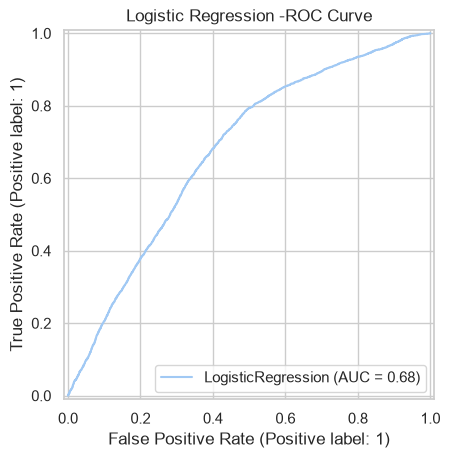

<Figure size 640x480 with 0 Axes>

: 

In [ ]:
RocCurveDisplay.from_estimator(log_reg,X_test,y_test)
plt.title('Logistic Regression -ROC Curve')
plt.show()
save('06_Logistic_regression_curve')

In [ ]:
# Random Forest Classifier
rf = RandomForestClassifier(
    n_estimators= 200,
    max_depth=10,
    min_samples_split=20,
    random_state=42,
    class_weight='balanced'
)

rf.fit(X_train, y_train)

#Predictions
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

# Evaluation
print("=== Random Forest Results====")
print(classification_report(y_test, y_pred_rf))

print('Confusion Matrix:')
print(confusion_matrix(y_test,y_pred_rf))
print(accuracy_score(y_test, y_pred_rf))

print("\nROC_AUC Score", round(roc_auc_score(y_test, y_prob_rf),4))

=== Random Forest Results====
              precision    recall  f1-score   support

           0       0.92      0.52      0.67     17642
           1       0.30      0.82      0.44      4463

    accuracy                           0.58     22105
   macro avg       0.61      0.67      0.56     22105
weighted avg       0.80      0.58      0.62     22105

Confusion Matrix:
[[9260 8382]
 [ 798 3665]]
0.5847093417778783

ROC_AUC Score 0.7256


: 

               Features  Importance
8          Waiting_Days    0.550456
9                Timing    0.212458
1                   Age    0.099457
7          SMS_received    0.046833
11  Appointment_Weekday    0.021815
10            Age_Group    0.021714
0                Gender    0.010789
6              Handicap    0.008603
2           Scholarship    0.008599
3          Hypertension    0.008070
5            Alcoholism    0.006036
4              Diabetes    0.005169


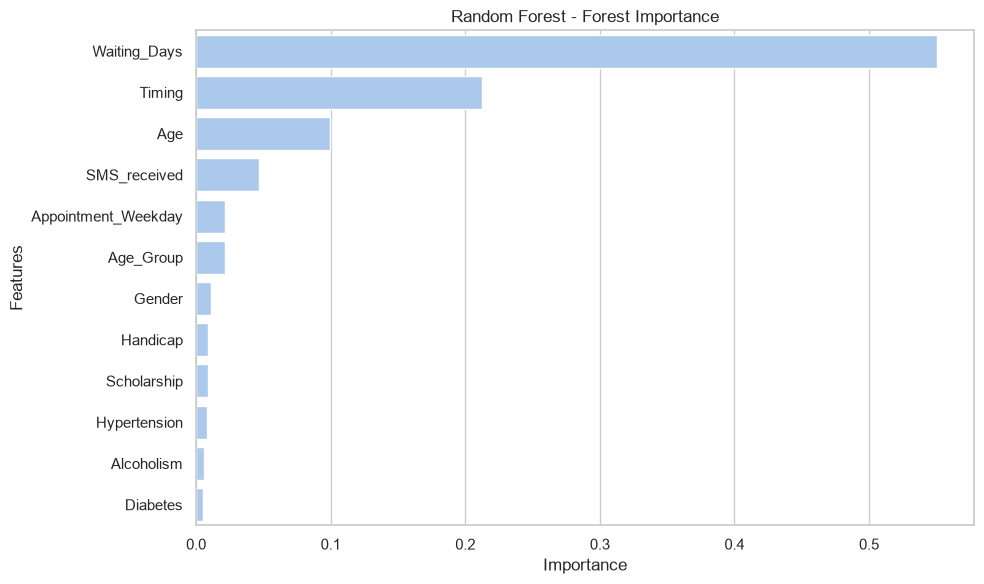

<Figure size 640x480 with 0 Axes>

: 

In [ ]:
# Feature Importance
Feature_importance = pd.DataFrame({
    'Features': X_train.columns,
    'Importance': rf.feature_importances_
    }).sort_values('Importance', ascending= False)

print(Feature_importance)

#plot
plt.figure(figsize=(10, 6))
sns.barplot(data=Feature_importance, x='Importance', y='Features')
plt.title("Random Forest - Forest Importance")
plt.tight_layout()
plt.show()
save('07_random_forest_features_importance')

In [ ]:
from xgboost import XGBClassifier


: 

In [ ]:
# ======================
# XGBoost Model
# ======================

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=4,          # helps with class imbalance (approx 80/20)
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

xgb.fit(X_train, y_train)

# Predictions
y_pred_xgb = xgb.predict(X_test)
y_prob_xgb = xgb.predict_proba(X_test)[:, 1]

# Evaluation
print("===== XGBoost Results =====")
print(classification_report(y_test, y_pred_xgb))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))
print("\nAccuracy:", round(accuracy_score(y_test, y_pred_xgb), 4))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob_xgb), 4))


===== XGBoost Results =====
              precision    recall  f1-score   support

           0       0.91      0.54      0.68     17642
           1       0.31      0.80      0.44      4463

    accuracy                           0.59     22105
   macro avg       0.61      0.67      0.56     22105
weighted avg       0.79      0.59      0.63     22105


Confusion Matrix:
[[9588 8054]
 [ 907 3556]]

Accuracy: 0.5946
ROC-AUC Score: 0.7246


: 

                Feature  Importance
9                Timing    0.475400
8          Waiting_Days    0.196024
10            Age_Group    0.050527
1                   Age    0.045240
7          SMS_received    0.043937
0                Gender    0.031339
2           Scholarship    0.028154
5            Alcoholism    0.028042
3          Hypertension    0.026547
11  Appointment_Weekday    0.026519
6              Handicap    0.025626
4              Diabetes    0.022645


C:\Users\afola\AppData\Local\Temp\ipykernel_2040\626653611.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_importance, x='Importance', y='Feature', palette='magma')


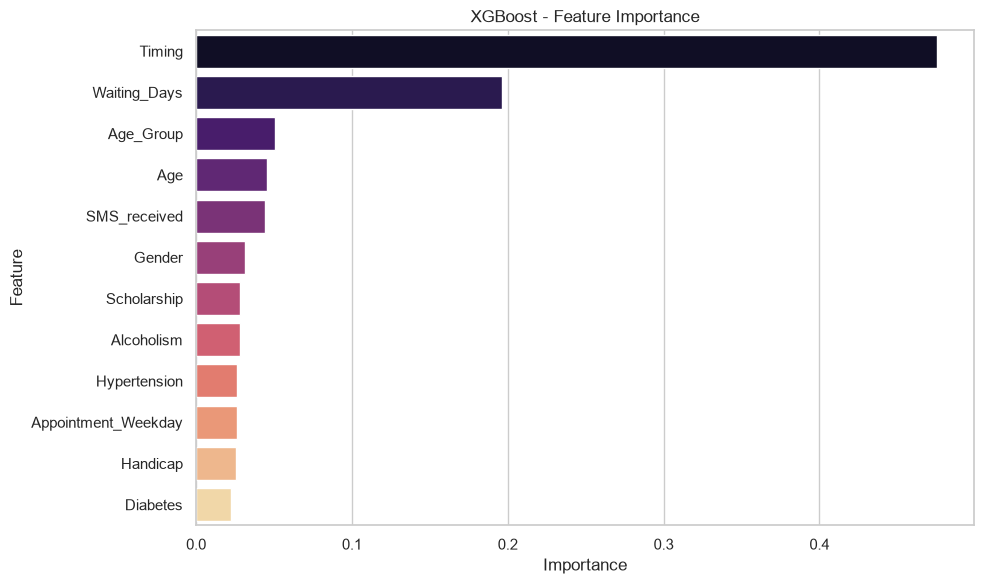

<Figure size 640x480 with 0 Axes>

: 

In [ ]:
# Feature Importance
xgb_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb.feature_importances_
}).sort_values('Importance', ascending=False)

print(xgb_importance)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=xgb_importance, x='Importance', y='Feature', palette='magma')
plt.title('XGBoost - Feature Importance')
plt.tight_layout()
plt.show()
save('08_XGBoost-Feature_Importance')

# Predictive Modelling – Summary
### Objective
#### The goal of this section was to build a machine learning model that can identify patients at higher risk of missing their hospital appointments, and to understand which factors the models rely on most.
### Approach
#### Three classification models were trained on the cleaned dataset using the same features and train-test split (80/20, stratified):
#### Logistic Regression – interpretable linear baseline
#### XGBoost – gradient boosting model for comparison
#### The target variable was No_Show_Binary (1 = patient missed the appointment, 0 = patient attended). Class imbalance was handled using class_weight='balanced' (Logistic Regression & Random Forest) and scale_pos_weight (XGBoost).
### Key observations:
#### Both tree-based models (Random Forest and XGBoost) significantly outperformed Logistic Regression.
#### Random Forest and XGBoost delivered almost identical predictive power (AUC ≈ 0.725).
#### The models prioritise recall for the no-show class, meaning they are better at catching patients who are likely to miss appointments (useful for risk flagging) than at avoiding false alarms.
### Feature Importance
#### Both Random Forest and XGBoost ranked the features in a very consistent way:
### Top predictors:
#### Waiting time related features (Waiting_Days and Timing) – by far the strongest drivers
#### Age-related features (Age and Age_Group)
#### SMS_received
### Weaker contributions from Gender, Scholarship, and clinical conditions
#### This result strongly reinforces the earlier exploratory and SQL findings: the longer a patient waits between scheduling and the appointment date, the higher the chance they will not show up.
### Conclusion
#### The machine learning models confirm that waiting time is the dominant factor influencing appointment attendance. Random Forest (AUC = 0.726) is selected as the primary model for this project due to its strong performance and highly interpretable feature importance ranking. XGBoost produced nearly identical results and serves as a robust supporting model.
#### These models can be used to flag high-risk appointments in advance, particularly those with long waiting times and no SMS reminder, allowing the hospital to prioritise targeted interventions.


: 